In [ ]:
!pip install torchinfo
!pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 3.8 MB/s eta 0:00:00


### CNN Image Classification Project
Golas:
* Train a small CNN baseline model
* Use train/validation transforms and DataLoaders

### 1. Data Preparation Step
Load the CIFAR100 dataset. Define transformations for training and testing.
For baseline model we will not use any data augumentation.
For both training and testing, we'll only normalize and convert to a tensor.

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms

# Load CIFAR100 datasets
# The dataset is dowloaded without applying transforms transforms=None by default
train_dataset = torchvision.datasets.CIFAR100(root='./data', train=True, download=True)
test_dataset = torchvision.datasets.CIFAR100(root='./data', train=False, download=True)


Notes: Try regularization, use L1 or L2
Splits: change the split sizes

### 2. Data Inspection Step
* print initial raw data shapes and information

In [ ]:
print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of output labels: {len(train_dataset.targets)}")
print(f"Training data input shape: {train_dataset.data.shape}")
print(f"Number of test samples: {len(test_dataset)}")
print(f"Number of test output labels: {len(test_dataset.targets)}")

Number of training samples: 50000
Number of output labels: 50000
Training data input shape: (50000, 32, 32, 3)
Number of test samples: 10000
Number of test output labels: 10000


####Dataset details
dataset contains 50000 training samples and 10000 test samples
the input shape (50000, 32, 32, 3) means
50000 images of 32x32 pixels and 3 color channels Red, Blue, Green (RGB)


#### Label Details
* list class label names for the dataset. CIFAR100 has 20 coarse labels and 100 fine labels within those 20 super classes.
* the labels are from 0-99

In [ ]:
# get the class names from the dataset CIFAR100
fine_labels = train_dataset.classes

#print samples class names
print(f"Total fine classes: {len(fine_labels)}")
print("First 5 fine labels:", fine_labels[:5])

print("----")

print("Last 5 fine labels:", fine_labels[-5:])

Total fine classes: 100
First 5 fine labels: ['apple', 'aquarium_fish', 'baby', 'bear', 'beaver']
----
Last 5 fine labels: ['whale', 'willow_tree', 'wolf', 'woman', 'worm']


* list the coarse class names for CIFAR100 dataset from the raw dataset
* will use it to check class distribution on the coarse labels

In [ ]:
import os
import pickle

def get_cifar100_coarse_metadata(data_dir='./data'):
    # Path to the meta file unzipped by PyTorch
    meta_path = os.path.join(data_dir, 'cifar-100-python', 'meta')

    with open(meta_path, 'rb') as f:
        meta_dict = pickle.load(f, encoding='utf-8')

    # Extracts ['aquatic_mammals', 'fish', ...]
    return meta_dict['coarse_label_names']

# Fetch the official superclass list directly from the raw files
coarse_classes = get_cifar100_coarse_metadata()
print(coarse_classes)
print(f"Total coarse class: {len(coarse_classes)}")

['aquatic_mammals', 'fish', 'flowers', 'food_containers', 'fruit_and_vegetables', 'household_electrical_devices', 'household_furniture', 'insects', 'large_carnivores', 'large_man-made_outdoor_things', 'large_natural_outdoor_scenes', 'large_omnivores_and_herbivores', 'medium_mammals', 'non-insect_invertebrates', 'people', 'reptiles', 'small_mammals', 'trees', 'vehicles_1', 'vehicles_2']
Total coarse class: 20


#### Check sample data and show sample image from the training dataset

In [ ]:
# print train sample target labels
print(train_dataset.targets[:5])

# map target labels to fine labels
for i in train_dataset.targets[:5]:
    print(fine_labels[i])

[19, 29, 0, 11, 1]
cattle
dinosaur
apple
boy
aquarium_fish


#### Look at sample images by dispalying them


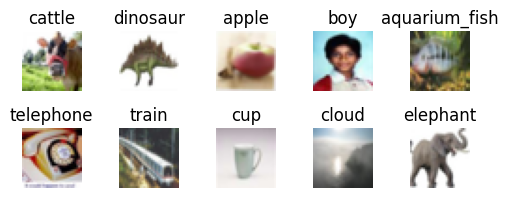

In [ ]:
from matplotlib import pyplot as plt

# display 10 sample images from the train dataset
plt.figure(figsize=(5, 5))

for i in range(10):
    plt.subplot(5, 5, i + 1)
    plt.imshow(train_dataset.data[i])
    plt.title(fine_labels[train_dataset.targets[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Check class distribution to check whether the classes are balanced.
import numpy as np

unique, counts = np.unique(train_dataset.targets, return_counts=True)

for label, count in zip(unique, counts):
    print(fine_labels[label], count)

apple 500
aquarium_fish 500
baby 500
bear 500
beaver 500
bed 500
bee 500
beetle 500
bicycle 500
bottle 500
bowl 500
boy 500
bridge 500
bus 500
butterfly 500
camel 500
can 500
castle 500
caterpillar 500
cattle 500
chair 500
chimpanzee 500
clock 500
cloud 500
cockroach 500
couch 500
crab 500
crocodile 500
cup 500
dinosaur 500
dolphin 500
elephant 500
flatfish 500
forest 500
fox 500
girl 500
hamster 500
house 500
kangaroo 500
keyboard 500
lamp 500
lawn_mower 500
leopard 500
lion 500
lizard 500
lobster 500
man 500
maple_tree 500
motorcycle 500
mountain 500
mouse 500
mushroom 500
oak_tree 500
orange 500
orchid 500
otter 500
palm_tree 500
pear 500
pickup_truck 500
pine_tree 500
plain 500
plate 500
poppy 500
porcupine 500
possum 500
rabbit 500
raccoon 500
ray 500
road 500
rocket 500
rose 500
sea 500
seal 500
shark 500
shrew 500
skunk 500
skyscraper 500
snail 500
snake 500
spider 500
squirrel 500
streetcar 500
sunflower 500
sweet_pepper 500
table 500
tank 500
telephone 500
television 500
tiger

We can see that we have 500 samples of each of the 100 class in the training set so the class samples are balanced which is good for training and the model will not be biased to any specific class

### 3. Data preprocessing
* Compute mean and std for the CIFAR100 dataset to be used for normalization
* Normalize the data using the mean and standard deviation of the CIFAR100 dataset.

In [ ]:
from torch.utils.data import DataLoader, random_split

# compute mean and std deviation for the CIFAR100 dataset
# 1. Load dataset with only ToTensor (keeps pixels between 0.0 and 1.0)
temp_dataset = torchvision.datasets.CIFAR100(root='./data', train=True, download=True, transform=transforms.ToTensor())
loader = DataLoader(temp_dataset, batch_size=len(temp_dataset), shuffle=False, num_workers=2)

# 2. Extract all images to compute stats
images, _ = next(iter(loader))
print(f"images dataset shape: {images.shape}")

# 3. Compute mean and std across batch, height, and width dimensions (dim 0, 2, 3)
computed_mean = images.mean(dim=[0, 2, 3])
computed_std = images.std(dim=[0, 2, 3])

print("Computed Mean:", computed_mean)
print("Computed Std:", computed_std)

images dataset shape: torch.Size([50000, 3, 32, 32])
Computed Mean: tensor([0.5071, 0.4866, 0.4409])
Computed Std: tensor([0.2673, 0.2564, 0.2762])


#### Transform and Normalize to tensors and create data loaders


In [ ]:
# Define data transformations
# Apply normalization
transform_train = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=computed_mean.tolist(), std=computed_std.tolist()),
])

# For testing: Apply normalization
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=computed_mean.tolist(), std=computed_std.tolist()),
])

# Load CIFAR100 datasets
# The dataset variable from earlier steps is overwritten here to use the new transforms
train_dataset = torchvision.datasets.CIFAR100(root='./data', train=True,
                                              download=True, transform=transform_train)
test_dataset = torchvision.datasets.CIFAR100(root='./data', train=False,
                                             download=True, transform=transform_test)

# Define split sizes (Must add up to the total length of the dataset: 50,000)
train_size = 45000
val_size = 5000

# Set a manual seed so split is identical every time we run the script
generator = torch.Generator().manual_seed(42)

# Perform the random split
train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size],
                                          generator=generator)

# Create DataLoaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2) # No need to shuffle validation data
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Number of testing samples: {len(test_dataset)}")

Number of training samples: 45000
Number of validation samples: 5000
Number of testing samples: 10000


### 4. Check final data shapes of a smaple at index 0

In [ ]:
print(f"Shape: {train_dataset[0][0].shape}")
print(f"Label: {fine_labels[train_dataset[0][1]]}")


Shape: torch.Size([3, 32, 32])
Label: flatfish


#### We can see that RGB channels are now set in dim 0 in the torch tensor unlike as in the numpy array in the original dataset

### 5. Define the CNN Model

Create a simple CNN architecture consisting of convolutional layers, activation functions (ReLU), pooling layers, and fully connected layers. This model is designed for image classification tasks like CIFAR100.

The input to our CNN is a CIFAR10 image, which has dimensions `3x32x32` (3 channels for RGB, 32 pixels height, 32 pixels width).

Let's trace how the dimensions change through the layers:

1.  **Input**: `3x32x32`
2.  **`self.conv1`**: `nn.Conv2d(3, 32, kernel_size=3, padding=1)`
    *   `padding=1` ensures the output spatial dimensions remain the same after convolution.
    *   Output: `32x32x32`
3.  **`self.pool` (after `conv1`)**: `nn.MaxPool2d(kernel_size=2, stride=2)`
    *   This halves the height and width.
    *   Output: `32x16x16`
4.  **`self.conv2`**: `nn.Conv2d(32, 64, kernel_size=3, padding=1)`
    *   Output: `64x16x16`
5.  **`self.pool` (after `conv2`)**: `nn.MaxPool2d(kernel_size=2, stride=2)`
    *   Output: `64x8x8`
6.  **`self.conv3`**: `nn.Conv2d(64, 128, kernel_size=3, padding=1)`
    *   Output: `128x8x8`
7.  **`self.pool` (after `conv3`)**: `nn.MaxPool2d(kernel_size=2, stride=2)`
    *   Output: `128x4x4`

Therefore, before being fed into the first fully connected layer (`self.fc1`), the tensor has `128` channels, and its spatial dimensions are `4x4`. When this tensor is flattened using `x.view(-1, 128 * 4 * 4)`, it becomes a vector of size `128 * 4 * 4 = 2048`. This is the input size expected by `self.fc1`.

In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1) # 3 input channels (RGB), 32 output channels
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2) # Reduces dimensions by half
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(128 * 4 * 4, 512) # 128 channels * (32/2/2 = 8/2 = 4) * (32/2/2 = 4)
        self.fc2 = nn.Linear(512, 100) # 100 output fine classes for CIFAR100

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x))) # Conv1 -> ReLU -> Pool
        x = self.pool(F.relu(self.conv2(x))) # Conv2 -> ReLU -> Pool
        x = self.pool(F.relu(self.conv3(x))) # Conv3 -> ReLU -> Pool
        x = x.view(-1, 128 * 4 * 4) # Flatten the tensor for fully connected layers
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Instantiate the model
model = SimpleCNN()

# Move model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model.to(device)

print(f"Model moved to: {device}")

Model moved to: cpu


### 6. Get summary of the model architecture using torchinfo

In [ ]:
import torchinfo

# Print model summary
torchinfo.summary(model, input_size=(3, 32, 32), device=device)

Layer (type:depth-idx)                   Output Shape              Param #
SimpleCNN                                [1, 100]                  --
├─Conv2d: 1-1                            [32, 32, 32]              896
├─MaxPool2d: 1-2                         [32, 16, 16]              --
├─Conv2d: 1-3                            [64, 16, 16]              18,496
├─MaxPool2d: 1-4                         [64, 8, 8]                --
├─Conv2d: 1-5                            [128, 8, 8]               73,856
├─MaxPool2d: 1-6                         [128, 4, 4]               --
├─Linear: 1-7                            [1, 512]                  1,049,088
├─Linear: 1-8                            [1, 100]                  51,300
Total params: 1,193,636
Trainable params: 1,193,636
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 96.59
Input size (MB): 0.01
Forward/backward pass size (MB): 0.46
Params size (MB): 4.77
Estimated Total Size (MB): 5.25

### 8. Training and Evaluation Functions

Define functions for training one epoch and for evaluating the model on the validation set. The training function will iterate through the training data, perform a forward pass, calculate loss, backpropagate, and update weights. The evaluation function will calculate the model's accuracy on unseen data.

In [ ]:
import torch.nn as nn
import torch.optim as optim

# Define Loss function and Optimizer
loss_fn = nn.CrossEntropyLoss()
#optimizer = optim.Adam(model.parameters(), lr=1e-3)

# 1. the initial training shows no improvemnet in the validation and it diverges
# after just 5 epochs so try L2 regularizion by adding weight decay and retrain
#2. AdamW with Weight Decay (L2 Regularization decoupled from gradients)
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-3,           # Initial learning rate
    weight_decay=1e-4  # L2 regularization strength
)

In [ ]:
#from torch.optim.lr_scheduler import ReduceLROnPlateau

# 1. CrossEntropyLoss with Label Smoothing (Acts as regularization)
#loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
# 3. Learning Rate Scheduler (Reduces LR by 0.5 if validation loss plateaus for 3 epochs)
#scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3, verbose=True)

#print("Configured AdamW with Weight Decay (1e-4), Label Smoothing (0.1), and ReduceLROnPlateau Scheduler.")

In [ ]:
from torchmetrics.classification import MulticlassAccuracy

def train_epoch(model, train_loader, loss_fn, optimizer, device):
    model.train() # Set the model to training mode
    running_loss = 0.0
    # Can also use num_classes=len(fine_labels) instead of hardcoding
    train_accuracy = MulticlassAccuracy(num_classes=100).to(device)
    for data in train_loader:
        inputs, labels = data[0].to(device), data[1].to(device)

        optimizer.zero_grad() # Zero the parameter gradients

        outputs = model(inputs) # Forward pass
        loss = loss_fn(outputs, labels) # Calculate loss
        loss.backward() # Backward pass
        optimizer.step() # Optimize

        running_loss += loss.item() * inputs.size(0) # total loss for the epoch

        # update accuracy for the batch
        train_accuracy.update(outputs, labels)

    # average training loss for the epoch
    train_loss = running_loss / len(train_loader.dataset)
    return train_loss, train_accuracy.compute().item()

def evaluate_model(model, test_loader, loss_fn, device):
    model.eval() # Set the model to evaluation mode
    correct = 0.0
    total = 0.0
    running_loss = 0.0
    all_preds = []
    with torch.no_grad(): # Disable gradient calculations during evaluation
        for data in test_loader:
            images, labels = data[0].to(device), data[1].to(device)
            outputs = model(images)

            loss = loss_fn(outputs, labels) # Calculate loss
            running_loss += loss.item() * images.size(0) # total loss for the epoch

            # collect all predicted labels from each batch
            predicted = torch.argmax(outputs, 1) # get the predicted label
            all_preds.append(predicted)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    # collect total metric for the test dataset
    val_loss = running_loss / len(test_loader.dataset)
    val_accuracy = correct / total
    # Concatenate all batch tensors along the batch dimension (dim=0)
    predicted_classes = torch.cat(all_preds, dim=0)

    return val_loss, val_accuracy, predicted_classes


def train_model(model, train_loader, val_loader, loss_fn, optimizer,
                num_epochs, device):
  history = []           # collects metric for each epoch and returns it

  model.train()          # switch model to training mode

  for epoch in range(num_epochs):
    train_loss, train_accuracy = train_epoch(model, train_loader, loss_fn,
                                             optimizer, device)
    val_loss, val_accuracy, _= evaluate_model(model, val_loader, loss_fn, device)

    print(f"Epoch {epoch + 1}/{num_epochs},")
    print(f"- accuracy: {train_accuracy} - loss: {train_loss} - val_accuracy: {val_accuracy} - val_loss: {val_loss}")

    # store the information about the epoch in a history dictionary
    # for later use and plotting/printing the data
    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

  return history

##### Integrating Early Stopping into the Training Loop

Now, let's redefine the `train_model` function to utilize our new `EarlyStopping` class during training.

In [ ]:
import numpy as np
import torch

class EarlyStopping:
    """
    Early stops the training if validation loss doesn't improve after a given patience.
    """
    def __init__(self, patience=5, verbose=False, delta=0.0, path='checkpoint.pt'):
        self.patience = patience
        self.verbose = verbose
        self.counter = 0
        self.early_stop = False
        self.val_loss_min = np.Inf
        self.delta = delta
        self.path = path

    def __call__(self, val_loss, model):
        # Check if the validation loss has improved significantly
        if val_loss < self.val_loss_min - self.delta:
            self.save_checkpoint(val_loss, model)
            self.counter = 0
        else:
            self.counter += 1
            if self.verbose:
                print(f'EarlyStopping counter: {self.counter} out of {self.patience}')
            if self.counter >= self.patience:
                self.early_stop = True

    def save_checkpoint(self, val_loss, model):
        '''Saves model when validation loss decreases.'''
        if self.verbose:
            print(f'Validation loss decreased ({self.val_loss_min:.6f} --> {val_loss:.6f}).  Saving model ...')
        torch.save(model.state_dict(), self.path)
        self.val_loss_min = val_loss

In [ ]:
def train_model_with_early_stopping(model, train_loader, val_loader, loss_fn, optimizer, num_epochs, device, scheduler=None, patience=5):
    history = []
    # Initialize early stopping object
    early_stopping = EarlyStopping(patience=patience, verbose=True, path='best_model.pt')

    for epoch in range(num_epochs):
        train_loss, train_accuracy = train_epoch(model, train_loader, loss_fn, optimizer, device)
        val_loss, val_accuracy, _ = evaluate_model(model, val_loader, loss_fn, device)

        print(f"Epoch {epoch + 1}/{num_epochs},")
        print(f"- accuracy: {train_accuracy:.4f} - loss: {train_loss:.4f} - val_accuracy: {val_accuracy:.4f} - val_loss: {val_loss:.4f}")

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        })

        # Step the learning rate scheduler based on validation loss
        if scheduler is not None:
            scheduler.step(val_loss)

        # Check early stopping criteria
        early_stopping(val_loss, model)
        if early_stopping.early_stop:
            print("Early stopping triggered. Training stopped!")
            break

    # Load the best saved model state before returning
    model.load_state_dict(torch.load('best_model.pt'))
    return history

### 9. Run Training

Finally, we'll run the training loop for a specified number of epochs and evaluate the model on the test set to monitor its performance.

In [ ]:
num_epochs = 20

print("Starting training...")
history = train_model(model, train_loader, val_loader, loss_fn, optimizer,
                      num_epochs, device)

print('Finished Training!')


Starting training...
Epoch 1/20,
- accuracy: 0.15398666262626648 - loss: 3.5851845190684 - val_accuracy: 0.251 - val_loss: 3.0231238094329833
Epoch 2/20,
- accuracy: 0.3148336410522461 - loss: 2.7112800565083823 - val_accuracy: 0.3324 - val_loss: 2.6699580894470216
Epoch 3/20,
- accuracy: 0.4028981924057007 - loss: 2.3049365234798853 - val_accuracy: 0.3764 - val_loss: 2.42056860370636
Epoch 4/20,
- accuracy: 0.46604886651039124 - loss: 2.001373115793864 - val_accuracy: 0.3984 - val_loss: 2.340733616256714
Epoch 5/20,
- accuracy: 0.5226365923881531 - loss: 1.7489142858929105 - val_accuracy: 0.4072 - val_loss: 2.3377923599243164
Epoch 6/20,
- accuracy: 0.5805109739303589 - loss: 1.5092725995381673 - val_accuracy: 0.4066 - val_loss: 2.4409389320373536
Epoch 7/20,
- accuracy: 0.6331510543823242 - loss: 1.2949920200241936 - val_accuracy: 0.41 - val_loss: 2.528723484992981
Epoch 8/20,
- accuracy: 0.6828679442405701 - loss: 1.0883422604878743 - val_accuracy: 0.4054 - val_loss: 2.7120509918212

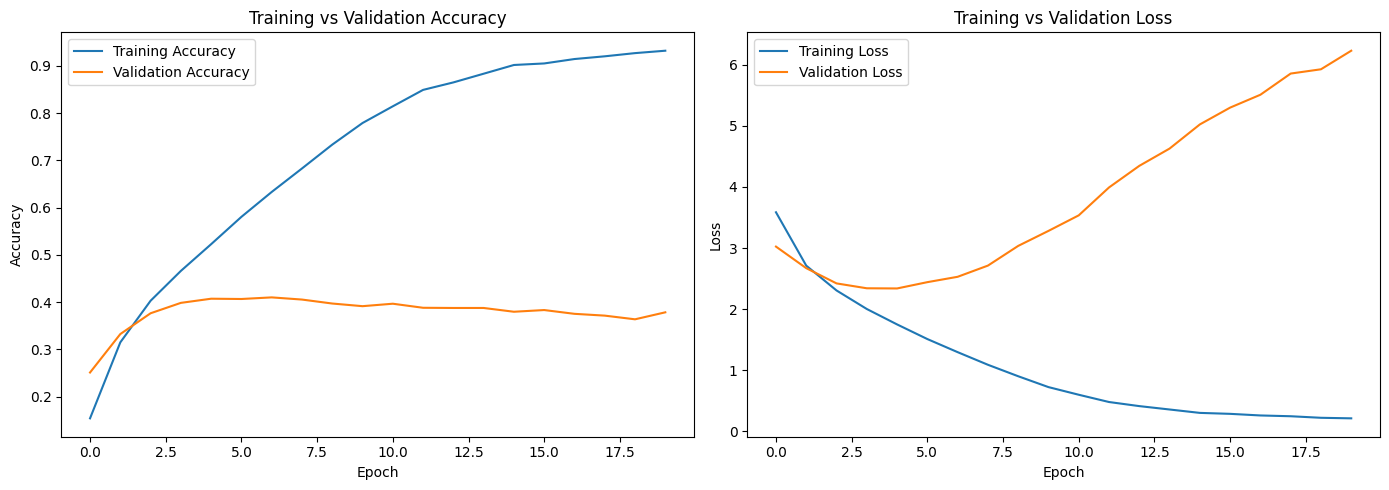

In [ ]:
#Plotting for baseline model with L2 regularization and AdamW -- 10/18
from matplotlib import pyplot as plt

plt.figure(figsize=(14, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)

plt.plot([h["train_accuracy"] for h in history], label="Training Accuracy")
plt.plot([h["val_accuracy"] for h in history], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)

plt.plot([h["train_loss"] for h in history], label="Training Loss")
plt.plot([h["val_loss"] for h in history], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

##### Plot training and validation Accuracy

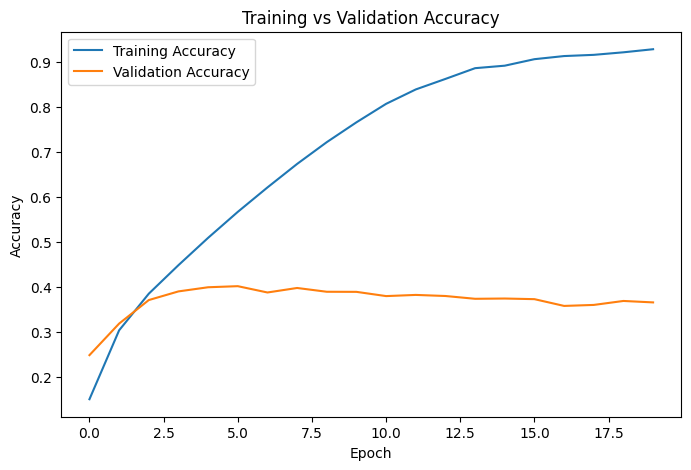

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot([h["train_accuracy"] for h in history], label="Training Accuracy")
plt.plot([h["val_accuracy"] for h in history], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.show()

##### Plot training and validation loss

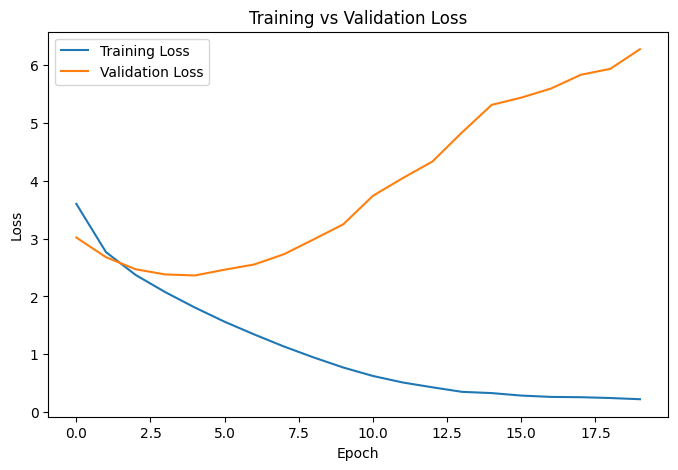

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot([h["train_loss"] for h in history], label="Training Loss")
plt.plot([h["val_loss"] for h in history], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.show()

### 10. Evaluation

* Run model evaluation using the test set



In [ ]:
# Final evaluation
test_loss, test_accuracy, predicted_classes = evaluate_model(model, test_loader, loss_fn, device)
print(f'Final Loss and Accuracy on the test set:')
print(f"Test Loss:  {test_loss}")
print(f"Test Accuracy: {test_accuracy}")

Final Loss and Accuracy on the test set:
Test Loss:  6.167675006866455
Test Accuracy: 0.3832


#### Get the predictions
 * test some samples and compare with actual labels

In [ ]:
# print predicted labels
print(predicted_classes.shape)
print(predicted_classes[:10])

torch.Size([10000])
tensor([30, 97, 27, 13, 71, 80,  1, 99, 71,  0])


In [ ]:
# Compare predicted vs actual labels
y_true = test_dataset.targets
y_pred = predicted_classes.cpu().numpy()

for i in range(10):
    print(
        "Actual:",
        fine_labels[y_true[i]],
        "| Predicted:",
        fine_labels[y_pred[i]]
    )

Actual: mountain | Predicted: dolphin
Actual: forest | Predicted: wolf
Actual: seal | Predicted: crocodile
Actual: mushroom | Predicted: bus
Actual: sea | Predicted: sea
Actual: tulip | Predicted: squirrel
Actual: camel | Predicted: aquarium_fish
Actual: butterfly | Predicted: worm
Actual: cloud | Predicted: sea
Actual: apple | Predicted: apple


##### Create Confusion Matrix

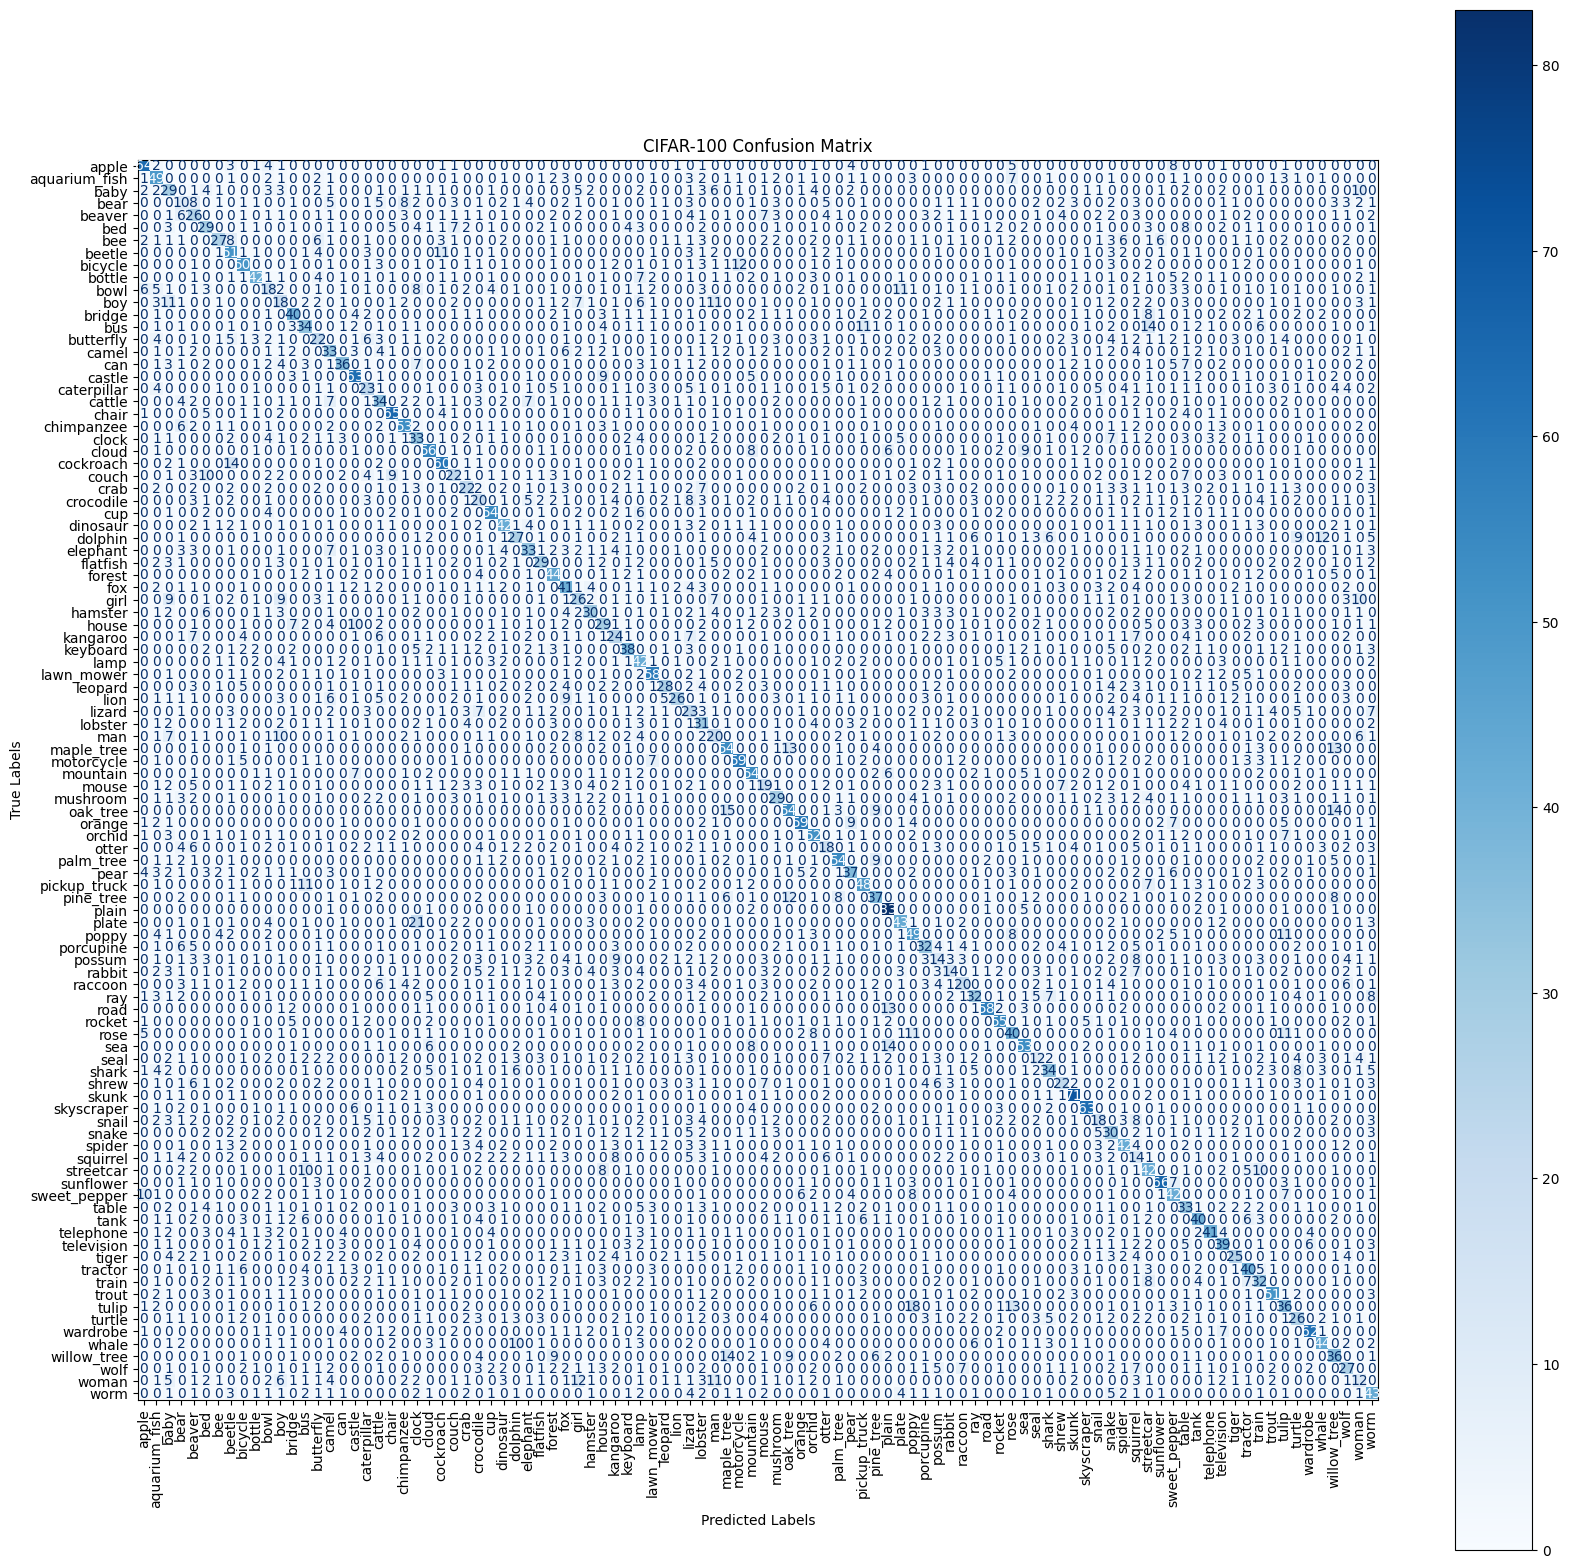

In [ ]:
# create confusion matrix usinf sklearn
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_true = test_dataset.targets
y_pred = predicted_classes.cpu().numpy()

# Compute via sklearn
cm = confusion_matrix(y_true, y_pred)

# Plot the matrix
fig, ax = plt.subplots(figsize=(20, 20))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=fine_labels)
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation='vertical', include_values=True)

plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.title("CIFAR-100 Confusion Matrix")
plt.show()

#### How to read the Confusion Matrix
The matrix is organized into columns and rows:

* The Vertical Rows represent the True Labels (the actual, real identity of the images).
* The Horizontal Columns represent the Predicted Labels by the model.

####The Diagonal Line: Correct Predictions

When you look at the matrix, the most striking feature is a distinct diagonal line running from the top-left corner down to the bottom-right corner.
* This line represents correct classifications.
* The number represents the counts of the time the model correctly predicted the image label i.e True label = Predicted Label
* The darker this diagonal line is, the better the model is performing i.e higher numbers

####The Off-Diagonal Blocks: Mistakes & confusions

Any points outside of that main diagonal line represent errors.
* A number in the Row: **"bus"** and Column: **"streetcar"**, means the model looked image of ***bus*** and incorrectly predicted it was a ***streetcar***.
* Because a 100x100 matrix tracks 10,000 possible combinations, these off-diagonal markers show us exactly which classes are constantly being wrongly predicted i.e higher the number means model regularly confuses between those classes so we should payattention to these and address them to improve model accuracy

####Color Bar: Darker for higher numbers
* Meaning higher the number of wrong prediction
* The darker the diagonal the better the model

####Conclusion:
* based on the matrix we can see that the model has highest incorrect prediction numbers for ***oak_tree*** and ***maple_tree*** and between other types of trees like pine_tree. So model confuses with visually similar images.
* highest numbers on the diagnoal are for ***plain 83*** and ***skunk 71*** indincating model can predict these labels with high probality


##### Create classification report
* This represents the model information in more human understandable form
* we can see the same results for higher Prec, Recall and F1 for Plain and skunk classes

In [ ]:
#Create a classification report
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=fine_labels))

               precision    recall  f1-score   support

        apple       0.63      0.64      0.63       100
aquarium_fish       0.39      0.49      0.43       100
         baby       0.23      0.29      0.26       100
         bear       0.12      0.10      0.11       100
       beaver       0.21      0.26      0.24       100
          bed       0.30      0.29      0.29       100
          bee       0.54      0.27      0.36       100
       beetle       0.36      0.51      0.42       100
      bicycle       0.43      0.50      0.46       100
       bottle       0.55      0.42      0.47       100
         bowl       0.21      0.18      0.19       100
          boy       0.17      0.18      0.17       100
       bridge       0.44      0.40      0.42       100
          bus       0.33      0.34      0.33       100
    butterfly       0.26      0.22      0.24       100
        camel       0.29      0.33      0.31       100
          can       0.51      0.36      0.42       100
       ca

Correctly classfied images: 3784


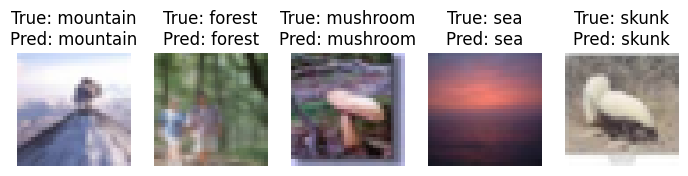

In [ ]:
# Display correctly classified images

correct = np.where(y_pred == y_true)[0]

print(f"Correctly classfied images: {len(correct)}")

plt.figure(figsize=(7, 7))

for i, idx in enumerate(correct[:5]):
    plt.subplot(5, 5, i+1)
    plt.imshow(test_dataset.data[idx])
    plt.title(
        f"True: {fine_labels[y_true[idx]]}\n"
        f"Pred: {fine_labels[y_pred[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

Incorrectly classfied images: 6216


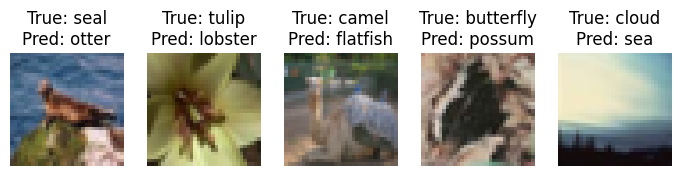

In [ ]:
# Display incorrectly classified images

incorrect = np.where(y_pred != y_true)[0]

print(f"Incorrectly classfied images: {len(incorrect)}")

plt.figure(figsize=(7, 7))

for i, idx in enumerate(incorrect[:5]):
    plt.subplot(5, 5, i+1)
    plt.imshow(test_dataset.data[idx])
    plt.title(
        f"True: {fine_labels[y_true[idx]]}\n"
        f"Pred: {fine_labels[y_pred[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

### 11. Improve the model with Data Augmention with tranform module
* Data Augmentation is applied only to training set
* Since we split the training set into train and validation set, we need to make sure the data transforms are only applied to train set
* Define a wrapper function which helps apply the transfor collectly only to train split and not to validation split
* Validation and test set use only Normalization

#####Build data augmentation pipeline

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torchvision.transforms import InterpolationMode
from torch.utils.data import DataLoader, random_split, Dataset

# Define the Universal transform Wrapper
class UniversalTransformWrapper(Dataset):
    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, index):
        # Retrieve the raw image and label directly from the subset (which has no base transform)
        img, label = self.subset[index]

        # Dynamically apply the wrapper's assigned transform
        if self.transform:
            img = self.transform(img)

        return img, label

    def __len__(self):
        return len(self.subset)

#define the mean and std for the cifar100 dataset, than recalculating it
computed_mean = [0.5071, 0.4866, 0.4409]
computed_std = [0.2673, 0.2564, 0.2762]

# Define data transformations
# Apply normalization
transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    # Rotate first and expand the canvas so corners aren't cut off or filled
    transforms.RandomRotation(degrees=15,
                              interpolation=InterpolationMode.BILINEAR,
                              fill=128, expand=True),

    #Crop it back down to 32x32 (this completely slices away the outer borders)
    transforms.RandomCrop(32, padding=4),

    transforms.RandomHorizontalFlip(p=0.5),
    # improve the contrast and sharpness of images
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),

    transforms.ToTensor(),
    transforms.Normalize(mean=computed_mean, std=computed_std),
])

# For testing: Apply normalization
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=computed_mean, std=computed_std),
])

# Load base train dataset with NO transforms
base_train_dataset = torchvision.datasets.CIFAR100(root='./data', train=True,
                                                   download=True, transform=None)

# Define split sizes (Must add up to the total length of the dataset: 50,000)
train_size = 45000
val_size = 5000

# Set a manual seed so split is identical every time we run the script
generator = torch.Generator().manual_seed(42)

# Perform the random split
train_subset, val_subset = random_split(base_train_dataset, [train_size, val_size],
                                          generator=generator)

# Wrap the subsets to give them their respective transforms
train_dataset = UniversalTransformWrapper(train_subset, transform_train)
val_dataset = UniversalTransformWrapper(val_subset, transform_test)

# Test set can be loaded directly with the evaluation pipeline
test_dataset = torchvision.datasets.CIFAR100(root='./data', train=False,
                                             download=True, transform=transform_test)

# Create DataLoaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2) # No need to shuffle validation data
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Number of testing samples: {len(test_dataset)}")

Number of training samples: 45000
Number of validation samples: 5000
Number of testing samples: 10000


#####Build model with one more conv2D layer to capture more image features
* do not apply Pooling to this 4th conv layer to avoid loosing spatial info


In [ ]:
import torch.nn as nn
import torch.nn.functional as F

class FourLayerCNN(nn.Module):
    def __init__(self):
        super(FourLayerCNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1) # 3 input channels (RGB), 32 output channels
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2) # Reduces dimensions by half
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(128, 512, kernel_size=3, padding=1)
        self.fc1 = nn.Linear(512 * 4 * 4, 512) # 512 channels * (32/2/2 = 8/2 = 4) * (32/2/2 = 4)
        self.fc2 = nn.Linear(512, 100) # 100 output fine classes for CIFAR100

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x))) # Conv1 -> ReLU -> Pool
        x = self.pool(F.relu(self.conv2(x))) # Conv2 -> ReLU -> Pool
        x = self.pool(F.relu(self.conv3(x))) # Conv3 -> ReLU -> Pool
        x = F.relu(self.conv4(x)) # Conv3 -> ReLU, No Pool layer to preseve 4x4 size
        x = x.view(-1, 512 * 4 * 4) # Flatten the tensor for fully connected layers
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Instantiate the model
model_aug = FourLayerCNN()

# Move model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model_aug.to(device)

print(f"Model moved to: {device}")

Model moved to: cpu


In [ ]:
#Print model Architechture with torchinfo
import torchinfo

# Print model summary
torchinfo.summary(model_aug, input_size=(3, 32, 32), device=device)

Layer (type:depth-idx)                   Output Shape              Param #
FourLayerCNN                             [1, 100]                  --
├─Conv2d: 1-1                            [32, 32, 32]              896
├─MaxPool2d: 1-2                         [32, 16, 16]              --
├─Conv2d: 1-3                            [64, 16, 16]              18,496
├─MaxPool2d: 1-4                         [64, 8, 8]                --
├─Conv2d: 1-5                            [128, 8, 8]               73,856
├─MaxPool2d: 1-6                         [128, 4, 4]               --
├─Conv2d: 1-7                            [512, 4, 4]               590,336
├─Linear: 1-8                            [1, 512]                  4,194,816
├─Linear: 1-9                            [1, 100]                  51,300
Total params: 4,929,700
Trainable params: 4,929,700
Non-trainable params: 0
Total mult-adds (Units.GIGABYTES): 1.31
Input size (MB): 0.01
Forward/backward pass size (MB): 0.53
Params size (MB): 19.72


#####Train and evaluate the model with data Augmentation

In [ ]:
import torch.optim as optim

# Define Loss function and Optimizer
loss_fn = nn.CrossEntropyLoss()

# set the otimizer for the correct model i.e model_aug params
optimizer = optim.Adam(model_aug.parameters(), lr=1e-3)
num_epochs = 50

print("Starting training...")
history_aug = train_model(model_aug, train_loader, val_loader, loss_fn, optimizer,
                      num_epochs, device)

print('Finished Training!')

Starting training...
Epoch 1/50,
- accuracy: 0.0687769427895546 - loss: 4.072114369837443 - val_accuracy: 0.127 - val_loss: 3.6919406799316405
Epoch 2/50,
- accuracy: 0.1493687480688095 - loss: 3.5750814376831053 - val_accuracy: 0.1958 - val_loss: 3.253734822463989
Epoch 3/50,
- accuracy: 0.20483100414276123 - loss: 3.2604122599283856 - val_accuracy: 0.2518 - val_loss: 3.080105066680908
Epoch 4/50,
- accuracy: 0.2450403869152069 - loss: 3.0484707919226754 - val_accuracy: 0.283 - val_loss: 2.8617782974243164
Epoch 5/50,
- accuracy: 0.27100318670272827 - loss: 2.8982709240807427 - val_accuracy: 0.33 - val_loss: 2.6819797758102415
Epoch 6/50,
- accuracy: 0.29939788579940796 - loss: 2.7585984688652885 - val_accuracy: 0.331 - val_loss: 2.6274067747116088
Epoch 7/50,
- accuracy: 0.32238951325416565 - loss: 2.653559371015761 - val_accuracy: 0.3332 - val_loss: 2.6444224113464356
Epoch 8/50,
- accuracy: 0.33596140146255493 - loss: 2.5718042672899033 - val_accuracy: 0.3582 - val_loss: 2.57569051

##### Plot training and validation accuracy and loss

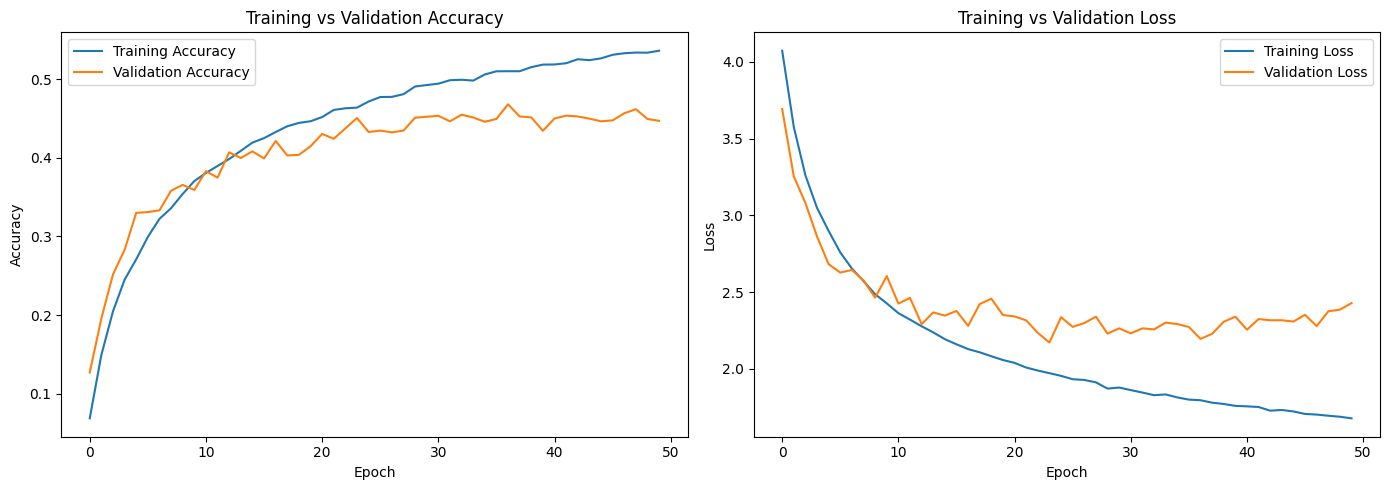

In [ ]:
#Plotting for Augumented model
from matplotlib import pyplot as plt

plt.figure(figsize=(14, 5))

# Plot Accuracy
plt.subplot(1, 2, 1)

plt.plot([h["train_accuracy"] for h in history_aug], label="Training Accuracy")
plt.plot([h["val_accuracy"] for h in history_aug], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

# Plot Loss
plt.subplot(1, 2, 2)

plt.plot([h["train_loss"] for h in history_aug], label="Training Loss")
plt.plot([h["val_loss"] for h in history_aug], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Evaluate model with data augmentation on the test set
aug_test_loss, aug_test_accuracy, aug_preds = evaluate_model(model_aug, test_loader, loss_fn, device)
print(f'Final Loss and Accuracy on the test set:')
print(f"Test Loss:  {aug_test_loss}")
print(f"Test Accuracy: {aug_test_accuracy}")

Final Loss and Accuracy on the test set:
Test Loss:  2.365345555114746
Test Accuracy: 0.4581


In [ ]:
# run some predictions with data augmentation model
outputs =  model_aug(test_dataset[11][0].unsqueeze(0).to(device))
print(outputs.shape)
print(f"logits:\n {outputs}")
prob = torch.softmax(outputs, dim=1)
print(f"probabilities:\n {prob}\n")

# print the predicted and the true label
print(f"Predicted class: {fine_labels[torch.argmax(outputs, dim=1).item()]}")
print(f"True class: {fine_labels[test_dataset.targets[11]]}")
print(f"Probality: {torch.max(prob).item():.4f}")

torch.Size([1, 100])
logits:
 tensor([[-18.6320,  -6.1780,  -4.2188,  -4.1764,  -4.7853,  -4.3374, -10.9639,
          -5.6491,  -7.0499,  -7.3950,  -6.9488,  -6.3760,  -5.8673,  -3.4944,
          -6.9361,  -4.6629,  -7.4628,  -7.3342,  -4.8798,  -5.4609,  -6.0306,
          -9.1068,  -6.6301,  -6.2728,  -5.3845,  -3.0706,  -2.2304,   0.5078,
          -7.5425,  -5.5280,  -4.8008,  -7.0001,  -4.8646,  -7.2984,  -6.8846,
          -6.6410,  -8.5448,  -4.2224,  -1.5468,  -4.9616,  -6.4142,  -6.7298,
          -4.3453,  -6.7219,  -0.3366,  -5.7198,  -6.7541, -10.4827,  -8.2380,
          -8.1654,  -4.5790,  -9.7882, -14.2545, -20.1996,  -9.2592,  -1.7846,
          -8.6051,  -8.9785,  -2.9152,  -7.6396, -13.4546,  -8.8530, -14.8941,
          -5.9624,  -4.6136,  -1.6958,  -4.7662,  -3.1594,  -9.5734,  -6.1176,
         -14.8638,  -9.9127,   0.2137,  -3.8821,  -1.5166,  -1.9769, -12.5596,
          -4.2924,  -2.0791,  -6.5619,  -2.0431,  -5.6344,  -9.2984, -14.5650,
          -6.9350,   0

##### Create Aggregate Level confusion matrix and visualize

TP: 4578, FP: 5422, FN: 5422, TN: 984578, TOTAL: 10000


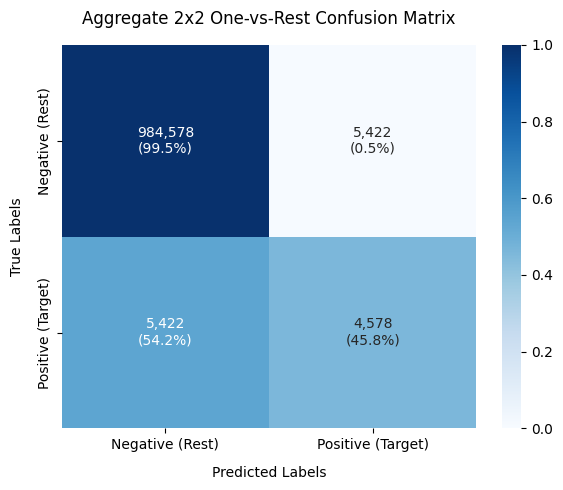

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from torchmetrics.functional.classification import multiclass_confusion_matrix

agg_cm = multiclass_confusion_matrix(aug_preds,
                                     torch.tensor(test_dataset.targets),
                                     num_classes=100)

# 2. Extract the aggregate counts
TP = int(agg_cm.diagonal().sum())
FP = int((agg_cm.sum(dim=0) - agg_cm.diagonal()).sum())
FN = int((agg_cm.sum(dim=1) - agg_cm.diagonal()).sum())
TOTAL_SAMPLES = int(agg_cm.sum())
TN = (TOTAL_SAMPLES*100) - (TP + FP + FN)

# print the computed numbers
print(f"TP: {TP}, FP: {FP}, FN: {FN}, TN: {TN}, TOTAL: {TOTAL_SAMPLES}")

# aggregate 2x2 data computed from the model predictions
# [ [TN, FP], [FN, TP] ]
binary_matrix = np.array([[TN, FP], [FN, TP]])

# Define labels for the matrix rows/columns
labels = ['Negative (Rest)', 'Positive (Target)']

# Calculate row-normalized values (percentages per row) for the visual color scale
# This prevents the massive TN count from drowning out the rest of the chart colors
row_sums = binary_matrix.sum(axis=1, keepdims=True)
normalized_matrix = np.where(row_sums > 0, binary_matrix / row_sums, 0.0)

# Create annotated text arrays showing both Raw Count and Row Percentage
annot_labels = np.empty_like(binary_matrix, dtype=object)
for i in range(2):
    for j in range(2):
        count = binary_matrix[i, j]
        pct = normalized_matrix[i, j] * 100
        annot_labels[i, j] = f"{count:,}\n({pct:.1f}%)"

# Plot using Seaborn Heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(
    normalized_matrix,          # Use normalized values for the background color gradients
    annot=annot_labels,         # Inject our custom text (Raw Count + Pct)
    fmt="",                     # Required to allow string formatting in annot
    cmap="Blues",               # Nice professional blue gradient colorway
    xticklabels=labels,
    yticklabels=labels,
    cbar=True,
    vmin=0, vmax=1              # Lock color scale from 0% to 100%
)

plt.title("Aggregate 2x2 One-vs-Rest Confusion Matrix", fontsize=12, pad=15)
plt.xlabel("Predicted Labels", fontsize=10, labelpad=10)
plt.ylabel("True Labels", fontsize=10, labelpad=10)
plt.tight_layout()
plt.show()

In [ ]:
import torch
from torchmetrics.classification import MulticlassPrecision, MulticlassRecall, MulticlassF1Score

# Convert targets and predictions to torch tensors
targets_tensor = torch.tensor(test_dataset.targets).to(device)
# ensure predictions are on the correct device as well
preds_tensor = aug_preds.to(device)

# Initialize torchmetrics for macro averaging
macro_precision_metric = MulticlassPrecision(num_classes=100, average='macro').to(device)
macro_recall_metric = MulticlassRecall(num_classes=100, average='macro').to(device)
macro_f1_metric = MulticlassF1Score(num_classes=100, average='macro').to(device)

# Calculate metrics
macro_precision = macro_precision_metric(preds_tensor, targets_tensor).item()
macro_recall = macro_recall_metric(preds_tensor, targets_tensor).item()
macro_f1 = macro_f1_metric(preds_tensor, targets_tensor).item()

print(f"Macro Precision (torchmetrics): {macro_precision:.4f}")
print(f"Macro Recall (torchmetrics):    {macro_recall:.4f}")
print(f"Macro F1-score (torchmetrics):  {macro_f1:.4f}")

Macro Precision (torchmetrics): 0.4874
Macro Recall (torchmetrics):    0.4578
Macro F1-score (torchmetrics):  0.4555


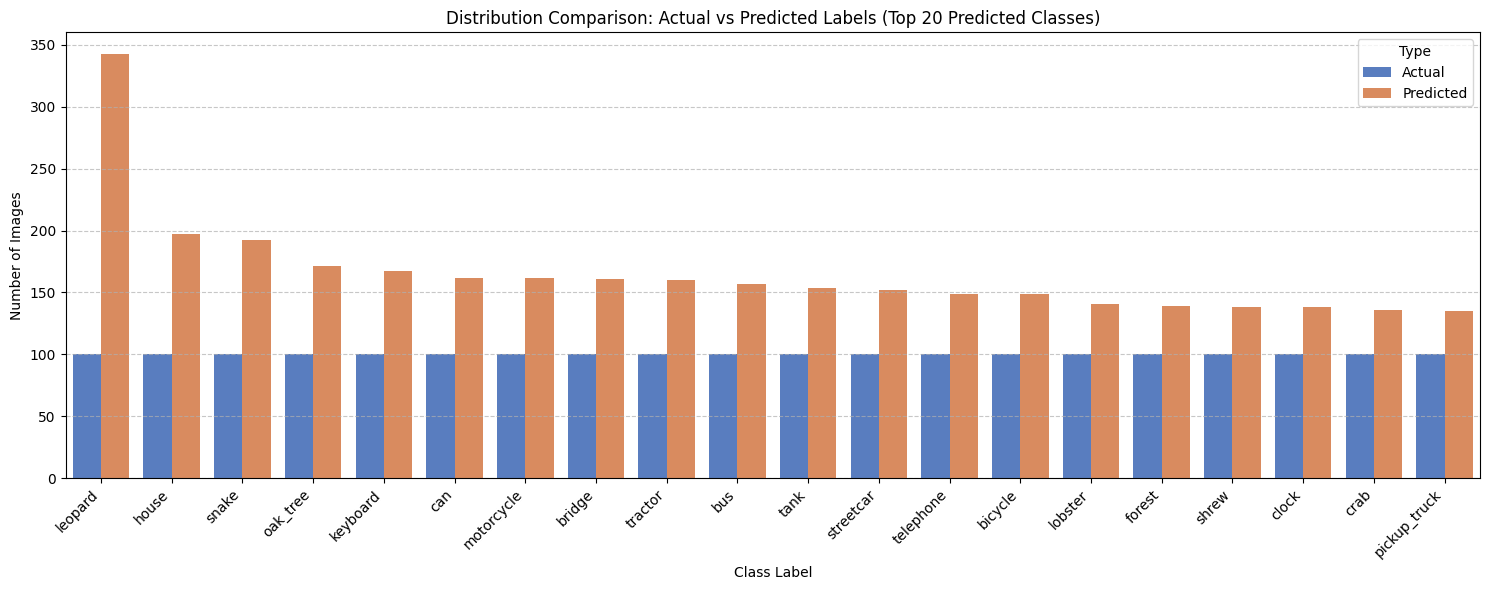

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare true and predicted arrays
y_true_arr = np.array(test_dataset.targets)
y_pred_arr = aug_preds.cpu().numpy()

# Count frequencies
true_counts = pd.Series(y_true_arr).value_counts().sort_index()
pred_counts = pd.Series(y_pred_arr).value_counts().sort_index()

# Create a DataFrame for plotting
dist_df = pd.DataFrame({
    'Class': [fine_labels[i] for i in range(100)],
    'Actual': [true_counts.get(i, 0) for i in range(100)],
    'Predicted': [pred_counts.get(i, 0) for i in range(100)]
})

# Focus on top 20 classes by prediction frequency to make the plot readable
top_classes = dist_df.sort_values(by='Predicted', ascending=False).head(20)

# Melt the DataFrame for Seaborn
melted_df = top_classes.melt(id_vars='Class', value_vars=['Actual', 'Predicted'],
                              var_name='Type', value_name='Count')

# Plot
plt.figure(figsize=(15, 6))
sns.barplot(x='Class', y='Count', hue='Type', data=melted_df, palette='muted')
plt.xticks(rotation=45, ha='right')
plt.title('Distribution Comparison: Actual vs Predicted Labels (Top 20 Predicted Classes)')
plt.xlabel('Class Label')
plt.ylabel('Number of Images')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

### 12. Transfer learning by using the ResNet18 ImageNet trained model
* assemble model with ResNet18 and train a new classifier head for CIFAR100 classes
* the ResNet18 is trained on Imagenet images which are 224x224 whereas teh cifar100 are 32x32 so upsamplng is needed
* upsampling applied in data pipeline using transforms
Upsampling is applied for all train, validation and test sets
* for normalization mean and std are used for the ImageNet datset instead of the CIFAR100 dataset

In [ ]:
import torch
import torch.nn as nn
from torchvision.models import resnet18, ResNet18_Weights

def get_cifar100_resnet18():
    """
    Assembles and returns a ResNet-18 model tailored for CIFAR-100 transfer learning.
    Returns:
        nn.Module: The assembled PyTorch model.
    """
    # 1. Load the pre-trained ResNet-18 model
    weights = ResNet18_Weights.DEFAULT
    model = resnet18(weights=weights)

    # 2. Freezing Strategy
    for param in model.parameters():
      param.requires_grad = False

    # 3. Swap out the original 1000-class head for a 100-class CIFAR-100 head
    # (Newly constructed modules have requires_grad=True by default)
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, 100)

    return model

# instantiate the model
model_tfr = get_cifar100_resnet18()

# Move model to GPU if available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
model_tfr.to(device)

print(f"Model moved to: {device}")

Model moved to: cuda:0


In [ ]:
# print model structure with torchinfo
import torchinfo

# Print model summary
torchinfo.summary(model_tfr, input_size=(1, 3, 224, 224), device=device)

Layer (type:depth-idx)                   Output Shape              Param #
ResNet                                   [1, 100]                  --
├─Conv2d: 1-1                            [1, 64, 112, 112]         (9,408)
├─BatchNorm2d: 1-2                       [1, 64, 112, 112]         (128)
├─ReLU: 1-3                              [1, 64, 112, 112]         --
├─MaxPool2d: 1-4                         [1, 64, 56, 56]           --
├─Sequential: 1-5                        [1, 64, 56, 56]           --
│    └─BasicBlock: 2-1                   [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-1                  [1, 64, 56, 56]           (36,864)
│    │    └─BatchNorm2d: 3-2             [1, 64, 56, 56]           (128)
│    │    └─ReLU: 3-3                    [1, 64, 56, 56]           --
│    │    └─Conv2d: 3-4                  [1, 64, 56, 56]           (36,864)
│    │    └─BatchNorm2d: 3-5             [1, 64, 56, 56]           (128)
│    │    └─ReLU: 3-6                    [1, 64, 56, 56]   

##### Upsample the cifar100 dataset using transforms


In [ ]:
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

# Data Transforms for train, validation and test sets
# Resizing to 224x224 and using ImageNet stats are vital for standard transfer learning
train_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Download and Load CIFAR-100
train_dataset = torchvision.datasets.CIFAR100(root='./data', train=True,
                                          download=True, transform=train_test_transform)
test_dataset = torchvision.datasets.CIFAR100(root='./data', train=False,
                                          download=True, transform=train_test_transform)

# Define split sizes (Must add up to the total length of the dataset: 50,000)
train_size = 45000
val_size = 5000

# Set a manual seed so split is identical every time we run the script
generator = torch.Generator().manual_seed(42)

# Perform the random split
train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size], generator=generator)

# Create DataLoaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2) # No need to shuffle validation data
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Number of testing samples: {len(test_dataset)}")

Number of training samples: 45000
Number of validation samples: 5000
Number of testing samples: 10000


##### Train the model and perform predictions

In [ ]:
import torch.nn as nn
import torch.optim as optim

# Define Loss function and Optimizer
loss_fn = nn.CrossEntropyLoss()

# set the otimizer for the correct model i.e model_tfr params
optimizer = optim.Adam(model_tfr.parameters(), lr=1e-3)

num_epochs = 4 # since the base model is already trained only need few epochs

print("Starting training...")
history_tfr = train_model(model_tfr, train_loader, val_loader, loss_fn, optimizer,
                      num_epochs, device)

print('Finished Training!')

Starting training...
Epoch 1/4,
- accuracy: 0.4186207056045532 - loss: 2.440536289045546 - val_accuracy: 0.5358 - val_loss: 1.7367331995010376
Epoch 2/4,
- accuracy: 0.5606842041015625 - loss: 1.6389393867492676 - val_accuracy: 0.5674 - val_loss: 1.567319790649414
Epoch 3/4,
- accuracy: 0.5922160148620605 - loss: 1.4877754852294922 - val_accuracy: 0.5726 - val_loss: 1.5295101977348327
Epoch 4/4,
- accuracy: 0.6093666553497314 - loss: 1.4062090243021648 - val_accuracy: 0.5832 - val_loss: 1.491914695262909
Finished Training!


In [ ]:
# Evaluate transfer learning model on the test set
tfr_test_loss, tfr_test_accuracy, _ = evaluate_model(model_tfr, test_loader, loss_fn, device)
print(f'Final Loss and Accuracy on the test set:')
print(f"Test Loss:  {tfr_test_loss}")
print(f"Test Accuracy: {tfr_test_accuracy}")

Final Loss and Accuracy on the test set:
Test Loss:  1.5295836490631103
Test Accuracy: 0.5795


In [ ]:
# run some predictions with transfer ResNet18 based model
outputs =  model_tfr(test_dataset[11][0].unsqueeze(0).to(device))
print(outputs.shape)
print(f"logits:\n {outputs}")
prob = torch.softmax(outputs, dim=1)
print(f"probabilities:\n {prob}\n")

# print the predicted and the true label
print(f"Predicted class: {fine_labels[torch.argmax(outputs, dim=1).item()]}")
print(f"True class: {fine_labels[test_dataset.targets[11]]}")
print(f"Probality: {torch.max(prob).item():.4f}")

torch.Size([1, 100])
logits:
 tensor([[-13.1501,  -6.6353,  -7.7352,  -5.2390,  -7.7616,  -9.2693,  -9.2624,
          -6.0116, -10.1983, -12.0898,  -8.2402,  -9.5183,  -7.4877,  -5.5075,
          -7.3657,  -9.2172,  -7.4486,  -9.3214,  -6.0428,  -5.9594,  -9.8462,
          -7.9457,  -9.6350, -10.2906,  -5.7294,  -6.2244,  -6.4060,  -3.1835,
          -9.9398,  -4.2108,  -5.0681,  -5.3811,  -5.1528, -11.7262,  -6.5965,
          -9.0106,  -9.1984,  -7.2028,  -6.4939,  -5.0380,  -7.4845,  -9.8736,
          -8.4275, -10.5325,  -5.3338,  -5.9176,  -8.8113,  -9.5473,  -7.9031,
          -8.4900,  -7.6080,  -2.5075, -10.1301, -14.7715, -11.1576,  -3.0244,
          -8.1555, -11.0682,  -6.9943, -10.5252,  -6.9135,  -8.4377,  -9.4825,
          -5.7218,  -5.8618,  -6.6691,  -6.4445,  -8.0243,  -7.4429,  -6.9994,
         -10.9912,  -7.9129,  -2.0457,  -8.7652,  -5.5676,  -0.5329,  -7.5945,
          -4.6041,  -7.0423,  -8.8675,  -5.5487,  -7.7275, -11.5785,  -8.4619,
          -7.8141,  -6

### 13. Sample model predictions from all models

In [ ]:
# Make a prediction on one image by all models
idx = 50

image = test_dataset.data[idx]  # raw image
image_tensor = test_dataset[idx][0].unsqueeze(0).to(device)

# use CNN1 for prediction and get the label and probablity
pred1 = model(image_tensor)
baseline_label = fine_labels[torch.argmax(pred1, dim=1).item()]
baseline_prob = torch.max(torch.softmax(pred1, dim=1)).item()

# use CNN2 for prediction and get the label and probablity
pred2 = model_aug(image_tensor)
aug_label = fine_labels[torch.argmax(pred2, dim=1).item()]
aug_prob = torch.max(torch.softmax(pred2, dim=1)).item()

# use CNN3 for prediction and get the label and probablity
#pred3 = model_tfr(image_tensor)
#tfr_label = fine_labels[torch.argmax(pred3, dim=1).item()]
#tfr_prob = torch.max(torch.softmax(pred3, dim=1)).item()

# print the results

print(f"True Label: {fine_labels[test_dataset.targets[idx]]}")
print(f"Baseline Label: {baseline_label}  Baseline Probablity: {baseline_prob:.4f}")
print(f"Augmented Label: {aug_label}  Augmented Probablity: {aug_prob:.4f}")
#print(f"Transfer Label: {tfr_label}  Transfer Probablity: {tfr_prob:.4f}")


True Label: beaver
Baseline Label: beaver  Baseline Probablity: 0.5779
Augmented Label: camel  Augmented Probablity: 0.1029


In [ ]:
# Make a prediction on one image by transfer model
idx = 50

image = test_dataset.data[idx]  # raw image
image_tensor = test_dataset[idx][0].unsqueeze(0).to(device)

# use CNN3 for prediction and get the label and probablity
pred3 = model_tfr(image_tensor)
tfr_label = fine_labels[torch.argmax(pred3, dim=1).item()]
tfr_prob = torch.max(torch.softmax(pred3, dim=1)).item()

# print the results

print(f"Transfer Label: {tfr_label}  Transfer Probablity: {tfr_prob:.4f}")


Transfer Label: beaver  Transfer Probablity: 0.5234


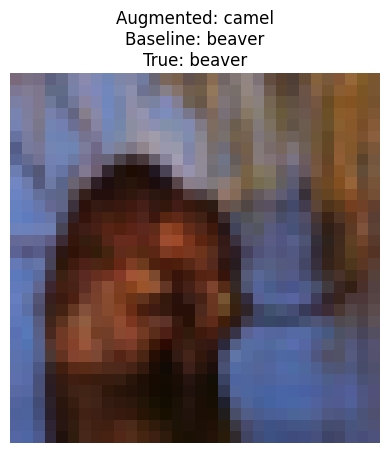

In [ ]:
#Display image with predicted and true labels:
plt.imshow(image)
plt.title(
    #f"Transfer: {tfr_label}\n"
    f"Augmented: {aug_label}\n"
    f"Baseline: {baseline_label}\n"
    f"True: {fine_labels[y_true[idx]]}"
)
plt.axis("off")
plt.show()

### 14. Compare Models - 10/18 Retrain

*  Only the Baseline and Augmented models



In [ ]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Metric": ["Training Accuracy", "Validation Accuracy", "Test Accuracy", "Test Loss", "Epochs Run"],
    "CNN #1 (Baseline)": [
        f"{history[-1]["train_accuracy"]:.4f}",
        f"{history[-1]["val_accuracy"]:.4f}",
        f"{test_accuracy:.4f}",
        f"{test_loss:.4f}",
        f"{history[-1]["epoch"]}"
    ],
    "CNN #2 (Augmented)": [
        f"{history_aug[-1]["train_accuracy"]:.4f}",
        f"{history_aug[-1]["val_accuracy"]:.4f}",
        f"{aug_test_accuracy:.4f}",
        f"{aug_test_loss:.4f}",
        f"{history_aug[-1]["epoch"]}"
    ],
    #"CNN #3 (Transfer)": [
     #   f"{history_tfr[-1]["train_accuracy"]:.4f}",
     #   f"{history_tfr[-1]["val_accuracy"]:.4f}",
      #  f"{tfr_test_accuracy:.4f}",
      #  f"{tfr_test_loss:.4f}",
      #  f"{history_tfr[-1]["epoch"]}"
    #]
})

display(comparison_df)

,Metric,CNN #1 (Baseline),CNN #2 (Augmented)
0,Training Accuracy,0.9321,0.5362
1,Validation Accuracy,0.3784,0.4470
2,Test Accuracy,0.3832,0.4578
3,Test Loss,6.1677,2.3654
4,Epochs Run,20,50


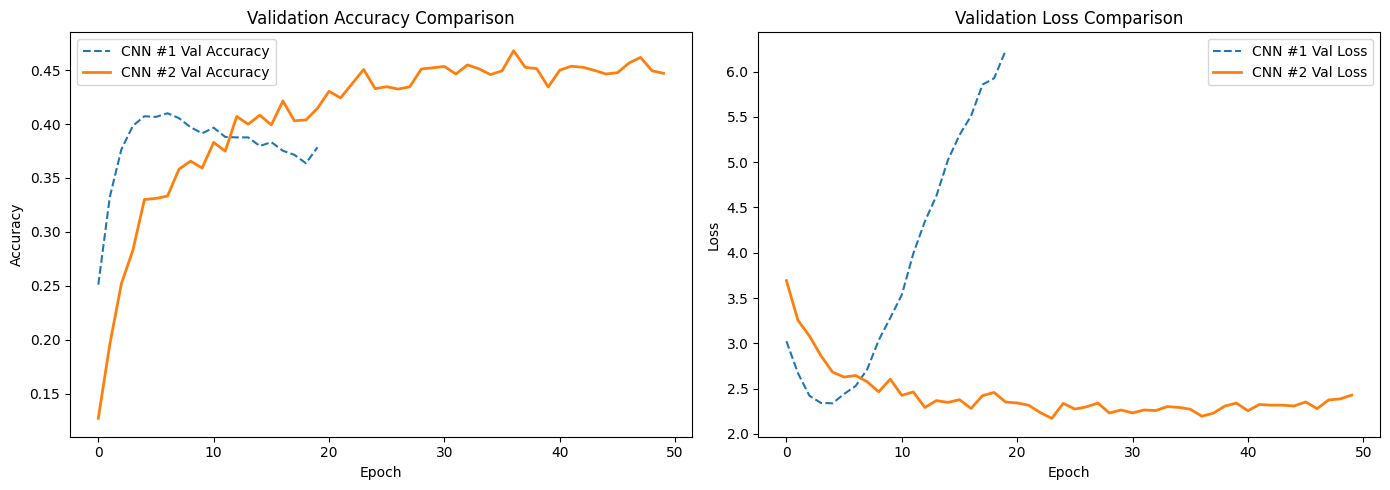

In [ ]:
#Plotting
plt.figure(figsize=(14, 5))

# Plot Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot([h["val_accuracy"] for h in history], label='CNN #1 Val Accuracy', linestyle='--')
plt.plot([h["val_accuracy"] for h in history_aug], label='CNN #2 Val Accuracy', linewidth=2)
# plt.plot([h["val_accuracy"] for h in history_tfr], label='CNN #3 Val Accuracy', linestyle=':')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot Validation Loss
plt.subplot(1, 2, 2)
plt.plot([h["val_loss"] for h in history], label='CNN #1 Val Loss', linestyle='--')
plt.plot([h["val_loss"] for h in history_aug], label='CNN #2 Val Loss', linewidth=2)
# plt.plot([h["val_loss"] for h in history_tfr], label='CNN #3 Val Loss', linestyle=':')
plt.title('Validation Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

### 14. Compare Models

In [ ]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Metric": ["Training Accuracy", "Validation Accuracy", "Test Accuracy", "Test Loss", "Epochs Run"],
    "CNN #1 (Baseline)": [
        f"{history[-1]["train_accuracy"]:.4f}",
        f"{history[-1]["val_accuracy"]:.4f}",
        f"{test_accuracy:.4f}",
        f"{test_loss:.4f}",
        f"{history[-1]["epoch"]}"
    ],
    "CNN #2 (Augmented)": [
        f"{history_aug[-1]["train_accuracy"]:.4f}",
        f"{history_aug[-1]["val_accuracy"]:.4f}",
        f"{aug_test_accuracy:.4f}",
        f"{aug_test_loss:.4f}",
        f"{history_aug[-1]["epoch"]}"
    ],
    #"CNN #3 (Transfer)": [
     #   f"{history_tfr[-1]["train_accuracy"]:.4f}",
     #   f"{history_tfr[-1]["val_accuracy"]:.4f}",
      #  f"{tfr_test_accuracy:.4f}",
      #  f"{tfr_test_loss:.4f}",
      #  f"{history_tfr[-1]["epoch"]}"
    #]
})

display(comparison_df)

,Metric,CNN #1 (Baseline),CNN #2 (Augmented)
0,Training Accuracy,0.9274,0.4545
1,Validation Accuracy,0.3658,0.4258
2,Test Accuracy,0.3784,0.4367
3,Test Loss,6.1162,2.2117
4,Epochs Run,20,20


In [ ]:
#Plotting
plt.figure(figsize=(14, 5))

# Plot Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot([h["val_accuracy"] for h in history], label='CNN #1 Val Accuracy', linestyle='--')
plt.plot([h["val_accuracy"] for h in history_aug], label='CNN #2 Val Accuracy', linewidth=2)
# plt.plot([h["val_accuracy"] for h in history_tfr], label='CNN #3 Val Accuracy', linestyle=':')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot Validation Loss
plt.subplot(1, 2, 2)
plt.plot([h["val_loss"] for h in history], label='CNN #1 Val Loss', linestyle='--')
plt.plot([h["val_loss"] for h in history_aug], label='CNN #2 Val Loss', linewidth=2)
# plt.plot([h["val_loss"] for h in history_tfr], label='CNN #3 Val Loss', linestyle=':')
plt.title('Validation Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

##### Tranfer Model Details and Plots

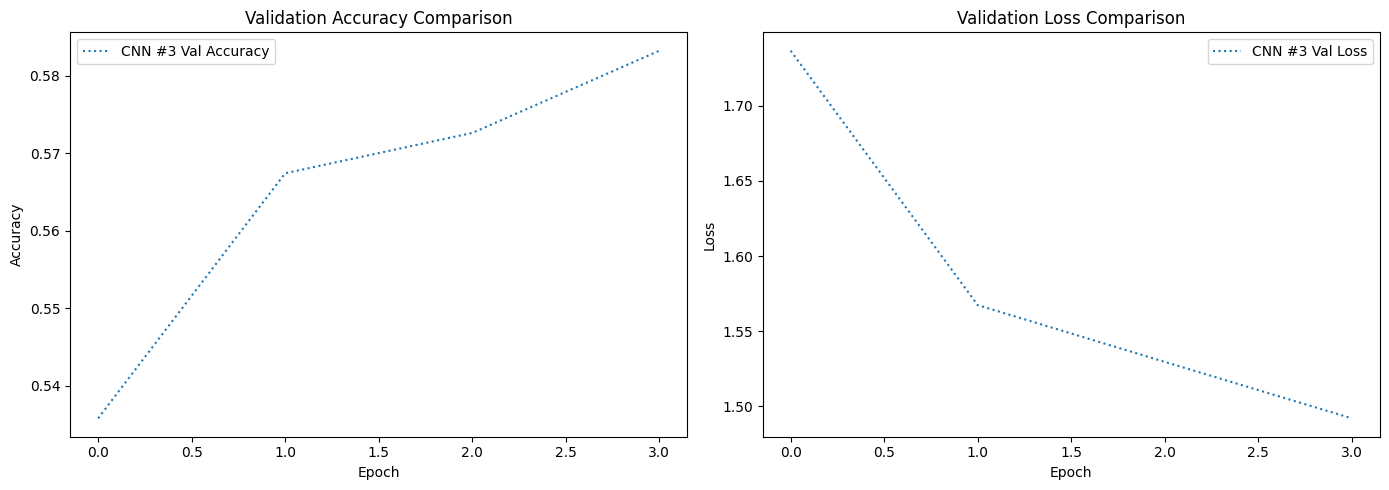

In [ ]:
#Plotting for transfer model
from matplotlib import pyplot as plt

plt.figure(figsize=(14, 5))

# Plot Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot([h["val_accuracy"] for h in history_tfr], label='CNN #3 Val Accuracy', linestyle=':')
plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot Validation Loss
plt.subplot(1, 2, 2)
plt.plot([h["val_loss"] for h in history_tfr], label='CNN #3 Val Loss', linestyle=':')
plt.title('Validation Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Metric": ["Training Accuracy", "Validation Accuracy", "Test Accuracy", "Test Loss", "Epochs Run"],
    "CNN #3 (Transfer)": [
        f"{history_tfr[-1]["train_accuracy"]:.4f}",
        f"{history_tfr[-1]["val_accuracy"]:.4f}",
        f"{tfr_test_accuracy:.4f}",
        f"{tfr_test_loss:.4f}",
        f"{history_tfr[-1]["epoch"]}"
    ]
})

display(comparison_df)


,Metric,CNN #3 (Transfer)
0,Training Accuracy,0.6094
1,Validation Accuracy,0.5832
2,Test Accuracy,0.5795
3,Test Loss,1.5296
4,Epochs Run,4


### 15. Observations and Reflections


*   The first time when i built and trained the CNN using lr=.01 the model accuracy was in teens i.e 14% then changed to lr=1e-3 but still came to 20s
*  Later i unfortunately lost all my work and redid the work and training
    * Do not know why but this time the first training gave train accuracy in 90% with validation accuracy in 37% so definitely model is overfitting but do not really understand why the initial model was so bad. Reinforces that some time the trainings can be very random and the reason for regularly saving the best model so far.
* Learnt how to use pandas for quick data reporting
* Adding early stopping in the baseline module would have helped as the validation loss starts to increase after 5 or 6 epochs.
* Build the ResNet18 based transfer Learning model but it takes a long time to train on the CPU and with limited resources on the free Google colab. managed to train one epoch out ot 2 without env being erased and get the following stat
  - Epoch 1/2
    - accuracy: 0.4165093004703522 - loss: 2.4460835604349773
    - val_accuracy: 0.5342 - val_loss: 1.7431557279586791
  - We can see the validation accuracy and loss are much better as compared to the other models trained but resource cost will be higher so there is a trade off
  - Could not get the model to fininsh training for 2 epochs on free resources so could not run on the test set 😞
* Comparision Table - For Best Model trained

    |   Metric   |    Baseline |  Augmented | Transfer |
    |:-----------|--------------:|--------------:|-------:|
    | train_accuracy | 0.5666    | 0.4545  | 0.4165  |
    | train loss | 1.5625    | 2.0308  | 2.4460  |
    | val_accuracy   | 0.4018   | 0.4258  | 0.5342  |
    | val loss | 2.4617    | 2.2470 | 1.7431  |
    | Epoch  | 6/20    | 20/20 | 1 |
